#**CAT BOOST REGRESSION**

0. Cài & import thư viện

In [ ]:
# Kết nối Google Drive để đọc file dữ liệu
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install catboost optuna scikit-learn pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 16.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

1. Đọc dữ liệu

In [ ]:
import pandas as pd

# Đường dẫn file
X_train_path = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/X_train.csv"
X_test_path  = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/X_test.csv"
y_train_path = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/y_train.csv"
y_test_path  = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/y_test.csv"

# Đọc dữ liệu
X_train = pd.read_csv(X_train_path)
X_test  = pd.read_csv(X_test_path)
y_train = pd.read_csv(y_train_path)
y_test  = pd.read_csv(y_test_path)

# Nếu y là dataframe 1 cột → chuyển về Series (khuyến nghị)
if y_train.shape[1] == 1:
    y_train = y_train.iloc[:, 0]
if y_test.shape[1] == 1:
    y_test = y_test.iloc[:, 0]

# Kiểm tra nhanh
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (25970, 20)
X_test shape : (6493, 20)
y_train shape: (25970,)
y_test shape : (6493,)


In [ ]:
print("Các cột trong X_train:")
print("\nKiểu dữ liệu các cột:")
print(X_train.dtypes)


Các cột trong X_train:

Kiểu dữ liệu các cột:
delivery_person_age        float64
delivery_person_ratings    float64
vehicle_condition            int64
type_of_order               object
type_of_vehicle             object
multiple_deliveries        float64
festival                    object
is_weekend                   int64
prep_time                  float64
distance_km                float64
weather_traffic             object
traffic_city                object
hour_sin                   float64
hour_cos                   float64
dow_sin                    float64
dow_cos                    float64
month_sin                  float64
month_cos                  float64
prev_time_taken            float64
rolling_avg_city           float64
dtype: object


In [ ]:
print(X_train.head(10))

   delivery_person_age  delivery_person_ratings  vehicle_condition  \
0                 33.0                      4.9                  2   
1                 32.0                      4.3                  0   
2                 22.0                      4.3                  0   
3                 29.0                      4.9                  1   
4                 36.0                      4.8                  1   
5                 36.0                      4.8                  2   
6                 21.0                      4.5                  1   
7                 39.0                      4.1                  0   
8                 38.0                      4.6                  0   
9                 27.0                      4.9                  2   

  type_of_order   type_of_vehicle  multiple_deliveries festival  is_weekend  \
0        Drinks           scooter                  1.0       No           0   
1        Buffet        motorcycle                  2.0       No        

2. Khai báo biến categorical

In [ ]:
cat_cols = [
    "type_of_order",
    "type_of_vehicle",
    "festival",
    "weather_traffic",
    "traffic_city",
    "vehicle_condition",
    "multiple_deliveries",
    "is_weekend"
]

for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [ ]:
print(X_train[cat_cols].dtypes)
print(X_test[cat_cols].dtypes)

type_of_order          object
type_of_vehicle        object
festival               object
weather_traffic        object
traffic_city           object
vehicle_condition      object
multiple_deliveries    object
is_weekend             object
dtype: object
type_of_order          object
type_of_vehicle        object
festival               object
weather_traffic        object
traffic_city           object
vehicle_condition      object
multiple_deliveries    object
is_weekend             object
dtype: object


In [ ]:
cat_features = [X_train.columns.get_loc(c) for c in cat_cols]

3. Tạo Pool

In [ ]:
train_pool = Pool(
    data=X_train,
    label=y_train,
    cat_features=cat_features
)

valid_pool = Pool(
    data=X_test,
    label=y_test,
    cat_features=cat_features
)

4. Khởi tạo & train CatBoost

In [ ]:
# Baseline model
baseline_model = CatBoostRegressor(
    loss_function='RMSE',

    # Tree & boosting
    depth=8,
    learning_rate=0.05,
    n_estimators=3000,

    # Regularization
    l2_leaf_reg=5,
    subsample=0.8,

    # Categorical handling
    one_hot_max_size=10,

    # Stability
    random_state=42,
    early_stopping_rounds=300,

    verbose=200
)

# Train
baseline_model.fit(
    train_pool,
    eval_set=valid_pool,
    use_best_model=True
)


0:	learn: 9.0532948	test: 9.1113057	best: 9.1113057 (0)	total: 80.8ms	remaining: 4m 2s
200:	learn: 3.8350210	test: 3.9787497	best: 3.9787497 (200)	total: 6.89s	remaining: 1m 35s
400:	learn: 3.6216074	test: 3.8903829	best: 3.8894873 (381)	total: 11.1s	remaining: 1m 12s
600:	learn: 3.4699069	test: 3.8699964	best: 3.8688263 (570)	total: 15.6s	remaining: 1m 2s
800:	learn: 3.3513082	test: 3.8675161	best: 3.8657187 (666)	total: 22.6s	remaining: 1m 2s
1000:	learn: 3.2316519	test: 3.8668822	best: 3.8653721 (891)	total: 27.3s	remaining: 54.5s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 3.865372052
bestIteration = 891

Shrink model to first 892 iterations.


CatBoostRegressor(depth=8, early_stopping_rounds=300, l2_leaf_reg=5, learning_rate=0.05, loss_function='RMSE', n_estimators=3000, one_hot_max_size=10, random_state=42, subsample=0.8, verbose=200)

5. Predict & đánh giá

In [ ]:
# ===== PREDICT =====
y_train_pred = baseline_model.predict(train_pool)
y_test_pred  = baseline_model.predict(valid_pool)

# ===== EVALUATION: TRAIN =====
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
mae_train  = mean_absolute_error(y_train, y_train_pred)
r2_train   = r2_score(y_train, y_train_pred)

# ===== EVALUATION: TEST =====
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
mae_test  = mean_absolute_error(y_test, y_test_pred)
r2_test   = r2_score(y_test, y_test_pred)

# ===== PRINT =====
print("=== BASELINE CATBOOST ===")
print("---- TRAIN SET ----")
print(f"RMSE: {rmse_train:.4f}")
print(f"MAE : {mae_train:.4f}")
print(f"R²  : {r2_train:.4f}")

print("\n---- TEST SET ----")
print(f"RMSE: {rmse_test:.4f}")
print(f"MAE : {mae_test:.4f}")
print(f"R²  : {r2_test:.4f}")

print("\nBest iteration:", baseline_model.get_best_iteration())

=== BASELINE CATBOOST ===
---- TRAIN SET ----
RMSE: 3.3245
MAE : 2.6747
R²  : 0.8745

---- TEST SET ----
RMSE: 3.8654
MAE : 3.1092
R²  : 0.8324

Best iteration: 891


6. Lưu model

In [ ]:
# Đường dẫn lưu model trong Google Drive
model_path = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/catboost_baseline_model.cbm"

# Lưu model CatBoost
baseline_model.save_model(model_path)
print(f"Đã lưu model thành công tại: {model_path}")

Đã lưu model thành công tại: /content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/catboost_baseline_model.cbm


7. Chia dữ liệu để tuning

In [ ]:
!pip install optuna

TRAIN_SUB   → học mô hình + tuning,
VAL_SUB     → chọn hyperparameter,
TEST        → đánh giá cuối (chỉ dùng 1 lần)

In [ ]:
# 1. CHIA TẬP TRAIN ĐỂ TUNING (QUAN TRỌNG)
# Không dùng X_test ở bước này!
X_train_sub, X_val_sub, y_train_sub, y_val_sub = train_test_split(
    X_train, y_train, test_size=0.2,
    random_state=42
)

train_pool_sub = Pool(X_train_sub, y_train_sub, cat_features=cat_features)
valid_pool_sub = Pool(X_val_sub, y_val_sub, cat_features=cat_features)

8. Optuna tuning

In [ ]:
def objective(trial):
    params = {
        "loss_function": "RMSE",

        # Cho phép Optuna chọn policy, hoặc bỏ dòng này để dùng mặc định (SymmetricTree)
        "grow_policy": trial.suggest_categorical("grow_policy", ["SymmetricTree", "Depthwise", "Lossguide"]),

        "depth": trial.suggest_int("depth", 6, 10),

        # Learning rate: thử dải rộng hơn
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1),

        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0),

        # Random strength giúp chống nhiễu
        "random_strength": trial.suggest_float("random_strength", 1e-9, 10.0, log=True),

        # Subsample chỉ hoạt động nếu bootstrap_type ko phải Bayesian (mặc định GPU là Bayesian)
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),

        # Quan trọng: Nếu chọn Lossguide/Depthwise thì cần giới hạn lá
        # "max_leaves": trial.suggest_int("max_leaves", 16, 64) if trial.params.get("grow_policy") != "SymmetricTree" else None,

        "iterations": 2000,
        "early_stopping_rounds": 100,
        "random_state": 42,
        "verbose": False
    }

    # Xử lý logic conditional parameter (nếu cần thiết cho grow_policy)
    if params["grow_policy"] == "Lossguide":
        params["max_leaves"] = trial.suggest_int("max_leaves", 16, 64)

    model = CatBoostRegressor(**params)

    model.fit(
        train_pool_sub,
        eval_set=valid_pool_sub,
        use_best_model=True
    )

    # Trả về kết quả tốt nhất trên tập Validation phụ
    return model.get_best_score()['validation']['RMSE']

# Chạy Optuna
print("Bắt đầu Tuning...")
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

print("Best RMSE (Validation Sub):", study.best_value)
print("Best Params:", study.best_params)

[I 2026-03-18 07:09:19,186] A new study created in memory with name: no-name-e86632dd-ff53-40f3-b7ed-1c02f8408336


Bắt đầu Tuning...


[I 2026-03-18 07:09:57,423] Trial 0 finished with value: 4.294736268084064 and parameters: {'grow_policy': 'Lossguide', 'depth': 9, 'learning_rate': 0.04019814724886322, 'l2_leaf_reg': 7.893192404915609, 'random_strength': 1.7821550008809675e-07, 'subsample': 0.6436736498070041, 'max_leaves': 21}. Best is trial 0 with value: 4.294736268084064.
[I 2026-03-18 07:10:05,508] Trial 1 finished with value: 4.212023387788912 and parameters: {'grow_policy': 'Depthwise', 'depth': 8, 'learning_rate': 0.09165822181271487, 'l2_leaf_reg': 6.971307291418795, 'random_strength': 0.33615426702733214, 'subsample': 0.783215140221446}. Best is trial 1 with value: 4.212023387788912.
[I 2026-03-18 07:10:53,148] Trial 2 finished with value: 3.7733584808429677 and parameters: {'grow_policy': 'SymmetricTree', 'depth': 10, 'learning_rate': 0.07065565144866158, 'l2_leaf_reg': 3.8127829881469966, 'random_strength': 0.03617822406881722, 'subsample': 0.9636666239060935}. Best is trial 2 with value: 3.773358480842967

Best RMSE (Validation Sub): 3.7249016969209077
Best Params: {'grow_policy': 'SymmetricTree', 'depth': 9, 'learning_rate': 0.043327854501194585, 'l2_leaf_reg': 9.866228233183977, 'random_strength': 0.0031615963373020153, 'subsample': 0.7614910437704149}


9. Train model tối ưu

In [ ]:
final_model = CatBoostRegressor(
    loss_function="RMSE",

    grow_policy=study.best_params["grow_policy"],
    depth=study.best_params["depth"],
    learning_rate=study.best_params["learning_rate"],
    l2_leaf_reg=study.best_params["l2_leaf_reg"],
    random_strength=study.best_params["random_strength"],
    subsample=study.best_params["subsample"],

    iterations=5000,
    early_stopping_rounds=300,
    random_state=42,
    verbose=200
)

final_model.fit(
    train_pool,      # FULL X_train
    eval_set=valid_pool,  # X_test chỉ dùng 1 lần
    use_best_model=True
)


0:	learn: 9.1443746	test: 9.2017351	best: 9.2017351 (0)	total: 97.3ms	remaining: 8m 6s
200:	learn: 3.8562260	test: 3.9764256	best: 3.9764256 (200)	total: 12.9s	remaining: 5m 9s
400:	learn: 3.6994492	test: 3.8972356	best: 3.8972355 (399)	total: 27.2s	remaining: 5m 12s
600:	learn: 3.5846070	test: 3.8728809	best: 3.8724450 (598)	total: 42.1s	remaining: 5m 7s
800:	learn: 3.4776474	test: 3.8623761	best: 3.8619333 (785)	total: 57.8s	remaining: 5m 2s
1000:	learn: 3.3733629	test: 3.8620355	best: 3.8614773 (929)	total: 1m 13s	remaining: 4m 53s
1200:	learn: 3.2637004	test: 3.8574557	best: 3.8574557 (1200)	total: 1m 29s	remaining: 4m 42s
1400:	learn: 3.1696141	test: 3.8599027	best: 3.8572004 (1215)	total: 1m 45s	remaining: 4m 32s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 3.857200414
bestIteration = 1215

Shrink model to first 1216 iterations.


CatBoostRegressor(depth=9, early_stopping_rounds=300, grow_policy='SymmetricTree', iterations=5000, l2_leaf_reg=9.866228233183977, learning_rate=0.043327854501194585, loss_function='RMSE', random_state=42, random_strength=0.0031615963373020153, subsample=0.7614910437704149, verbose=200)

In [ ]:
# Predict TRAIN
y_train_pred = final_model.predict(train_pool)

# Evaluation TRAIN
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
mae_train  = mean_absolute_error(y_train, y_train_pred)
r2_train   = r2_score(y_train, y_train_pred)

print("=== FINAL OPTUNA CATBOOST (TRAIN SET) ===")
print(f"RMSE: {rmse_train:.4f}")
print(f"MAE : {mae_train:.4f}")
print(f"R²  : {r2_train:.4f}")
print("Best iteration:", final_model.get_best_iteration())

y_test_pred = final_model.predict(valid_pool)

rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
mae  = mean_absolute_error(y_test, y_test_pred)
r2   = r2_score(y_test, y_test_pred)

print("=== FINAL OPTUNA CATBOOST (TEST SET) ===")
print(f"RMSE: {rmse:.4f}")
print(f"MAE : {mae:.4f}")
print(f"R²  : {r2:.4f}")
print("Best iteration:", final_model.get_best_iteration())


=== FINAL OPTUNA CATBOOST (TRAIN SET) ===
RMSE: 3.3524
MAE : 2.7015
R²  : 0.8724
Best iteration: 1215
=== FINAL OPTUNA CATBOOST (TEST SET) ===
RMSE: 3.8572
MAE : 3.1092
R²  : 0.8331
Best iteration: 1215


In [ ]:
# Đường dẫn lưu model trong Google Drive
model_path = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/catboost_optuna_model.cbm"

# Lưu model CatBoost
final_model.save_model(model_path)
print(f"Đã lưu model thành công tại: {model_path}")

Đã lưu model thành công tại: /content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/catboost_optuna_model.cbm


10. Feature Importance


=== PHÂN TÍCH & LOẠI BỎ BIẾN YẾU (CATBOOST) ===

Mức độ quan trọng của các biế:
                    feature  importance
10          weather_traffic   23.164802
9               distance_km   16.587011
0       delivery_person_age   15.932898
2         vehicle_condition   12.373911
1   delivery_person_ratings   11.375538
12                 hour_sin    4.911147
5       multiple_deliveries    3.871205
11             traffic_city    2.474633
6                  festival    2.205716
13                 hour_cos    1.858264
19         rolling_avg_city    1.600677
18          prev_time_taken    1.019078
4           type_of_vehicle    0.580538
14                  dow_sin    0.533082
8                 prep_time    0.511675
15                  dow_cos    0.434611
3             type_of_order    0.396737
16                month_sin    0.072314
7                is_weekend    0.052754
17                month_cos    0.043409


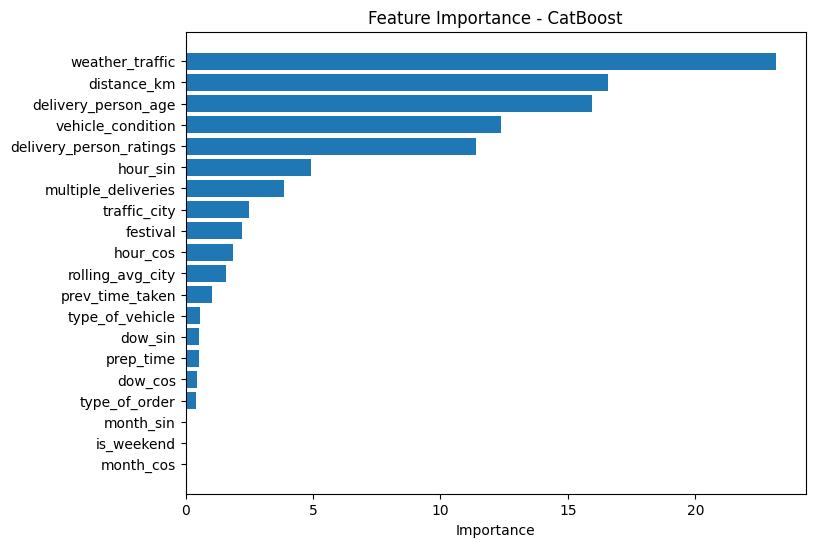

In [ ]:
import pandas as pd
import numpy as np
from catboost import Pool, CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
print("\n=== PHÂN TÍCH & LOẠI BỎ BIẾN YẾU (CATBOOST) ===")

# =================================================
# 1. FEATURE IMPORTANCE
# =================================================
feature_importance = final_model.get_feature_importance()
feature_names = X_train.columns

fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importance
}).sort_values(by="importance", ascending=False)

print("\nMức độ quan trọng của các biế:")
print(fi_df)

plt.figure(figsize=(8, len(fi_df)*0.3))
plt.barh(fi_df["feature"], fi_df["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Feature Importance - CatBoost")
plt.show()

11. Feature Selection

In [ ]:
# =================================================
# 1. DANH SÁCH NGƯỠNG CẦN THỬ (dùng quantile)
# =================================================
threshold_list = fi_df["importance"].quantile(
    [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
).values

results = []

# =================================================
# 2. LOOP QUA TỪNG NGƯỠNG (CHỈ DÙNG TRAIN + VAL)
# =================================================
for THRESHOLD in threshold_list:

    low_importance_features = fi_df[
        fi_df["importance"] < THRESHOLD
    ]["feature"].tolist()

    if len(low_importance_features) == 0:
        continue

    # Dataset rút gọn (TRAIN SUB + VAL SUB)
    X_train_sub_reduced = X_train_sub.drop(columns=low_importance_features)
    X_val_sub_reduced   = X_val_sub.drop(columns=low_importance_features)

    # Update cat_features
    if isinstance(cat_features[0], (int, np.integer)):
        original_cat_names = [X_train.columns[i] for i in cat_features]
    else:
        original_cat_names = cat_features

    new_cat_features = [
        col for col in original_cat_names
        if col in X_train_sub_reduced.columns
    ]

    train_pool = Pool(X_train_sub_reduced, y_train_sub, cat_features=new_cat_features)
    valid_pool = Pool(X_val_sub_reduced, y_val_sub, cat_features=new_cat_features)

    model_tmp = CatBoostRegressor(
        loss_function="RMSE",
        **study.best_params,
        iterations=5000,
        early_stopping_rounds=300,
        random_state=42,
        verbose=0
    )

    model_tmp.fit(train_pool, eval_set=valid_pool, use_best_model=True)

    y_pred = model_tmp.predict(valid_pool)
    rmse_tmp = np.sqrt(mean_squared_error(y_val_sub, y_pred))

    results.append({
        "threshold": THRESHOLD,
        "num_features_removed": len(low_importance_features),
        "rmse_val": rmse_tmp,
        "removed_features": low_importance_features
    })

    print(f"Threshold {THRESHOLD:.4f} | Removed {len(low_importance_features)} | VAL RMSE {rmse_tmp:.4f}")

Threshold 0.0704 | Removed 2 | VAL RMSE 3.7435
Threshold 0.4270 | Removed 4 | VAL RMSE 3.7419
Threshold 0.5267 | Removed 6 | VAL RMSE 3.7258
Threshold 0.8437 | Removed 8 | VAL RMSE 3.7250
Threshold 1.7295 | Removed 10 | VAL RMSE 3.6920
Threshold 2.3133 | Removed 12 | VAL RMSE 3.7021


In [ ]:
results_df = pd.DataFrame(results)
best_row = results_df.loc[results_df["rmse_val"].idxmin()]

best_threshold = best_row["threshold"]
best_removed_features = best_row["removed_features"]

print("\n=== BEST THRESHOLD TRÊN VALIDATION ===")
print(f"Best threshold: {best_threshold:.4f}")
print(f"Removed {len(best_removed_features)} features")
print(f"Best VAL RMSE: {best_row['rmse_val']:.4f}")


=== BEST THRESHOLD TRÊN VALIDATION ===
Best threshold: 1.7295
Removed 10 features
Best VAL RMSE: 3.6920


12. Train model reduced

In [ ]:
# Dataset full train reduced
X_train_reduced = X_train.drop(columns=best_removed_features)
X_test_reduced  = X_test.drop(columns=best_removed_features)

new_cat_features = [
    col for col in original_cat_names
    if col in X_train_reduced.columns
]

train_pool_reduced = Pool(X_train_reduced, y_train, cat_features=new_cat_features)
test_pool_reduced  = Pool(X_test_reduced, y_test, cat_features=new_cat_features)

reduced_model = CatBoostRegressor(
    loss_function="RMSE",
    **study.best_params,
    iterations=5000,
    early_stopping_rounds=300,
    random_state=42,
    verbose=200
)

reduced_model.fit(
    train_pool_reduced,
    eval_set=test_pool_reduced,
    use_best_model=True
)

0:	learn: 9.1033718	test: 9.1627141	best: 9.1627141 (0)	total: 52.9ms	remaining: 4m 24s
200:	learn: 3.8576440	test: 3.9588794	best: 3.9588768 (199)	total: 9.34s	remaining: 3m 43s
400:	learn: 3.7034205	test: 3.8587594	best: 3.8587594 (400)	total: 17.2s	remaining: 3m 17s
600:	learn: 3.6151061	test: 3.8358166	best: 3.8357928 (599)	total: 27.6s	remaining: 3m 22s
800:	learn: 3.5349410	test: 3.8220636	best: 3.8220636 (800)	total: 37.5s	remaining: 3m 16s
1000:	learn: 3.4691105	test: 3.8184928	best: 3.8184160 (998)	total: 47.1s	remaining: 3m 8s
1200:	learn: 3.4087742	test: 3.8166117	best: 3.8162823 (1182)	total: 58.4s	remaining: 3m 4s
1400:	learn: 3.3480800	test: 3.8151563	best: 3.8150627 (1398)	total: 1m 9s	remaining: 2m 58s
1600:	learn: 3.2968394	test: 3.8167743	best: 3.8146670 (1406)	total: 1m 18s	remaining: 2m 47s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 3.814667012
bestIteration = 1406

Shrink model to first 1407 iterations.


CatBoostRegressor(depth=9, early_stopping_rounds=300, grow_policy='SymmetricTree', iterations=5000, l2_leaf_reg=9.866228233183977, learning_rate=0.043327854501194585, loss_function='RMSE', random_state=42, random_strength=0.0031615963373020153, subsample=0.7614910437704149, verbose=200)

In [ ]:
# ----- TRAIN -----
y_train_pred = reduced_model.predict(train_pool_reduced)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
mae_train  = mean_absolute_error(y_train, y_train_pred)
r2_train   = r2_score(y_train, y_train_pred)

# ----- TEST -----
y_test_pred = reduced_model.predict(test_pool_reduced)
rmse_reduced = np.sqrt(mean_squared_error(y_test, y_test_pred))
mae_reduced  = mean_absolute_error(y_test, y_test_pred)
r2_reduced   = r2_score(y_test, y_test_pred)

print("\n=== CATBOOST SAU KHI FEATURE SELECTION ===")

print("\nTRAIN SET")
print(f"RMSE: {rmse_train:.4f}")
print(f"MAE : {mae_train:.4f}")
print(f"R²  : {r2_train:.4f}")

print("\nTEST SET")
print(f"RMSE: {rmse_reduced:.4f}")
print(f"MAE : {mae_reduced:.4f}")
print(f"R²  : {r2_reduced:.4f}")
print("Best iteration:", reduced_model.get_best_iteration())


=== CATBOOST SAU KHI FEATURE SELECTION ===

TRAIN SET
RMSE: 3.4552
MAE : 2.7882
R²  : 0.8644

TEST SET
RMSE: 3.8147
MAE : 3.0805
R²  : 0.8367
Best iteration: 1406


In [ ]:
# Đường dẫn lưu model trong Google Drive
model_path = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/catboost_reduced_model.cbm"

# Lưu model CatBoost
reduced_model.save_model(model_path)
print(f"Đã lưu model thành công tại: {model_path}")

Đã lưu model thành công tại: /content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/catboost_reduced_model.cbm


13. So sánh model

In [ ]:
print("\n=== SO SÁNH VỚI MODEL ĐẦY ĐỦ ===")
print(f"RMSE Full feature : {rmse:.5f}")
print(f"RMSE Reduced      : {rmse_reduced:.5f}")

if rmse_reduced <= rmse:
    print("=> ✅ Feature selection giúp mô hình tốt hơn / tương đương")
    best_model = reduced_model
    model_type = "Reduced"
else:
    print("=> ❌ Feature selection làm giảm hiệu quả → giữ model full")
    best_model = final_model
    model_type = "Full"


=== SO SÁNH VỚI MODEL ĐẦY ĐỦ ===
RMSE Full feature : 3.85720
RMSE Reduced      : 3.81467
=> ✅ Feature selection giúp mô hình tốt hơn / tương đương


In [ ]:
14. Visualization

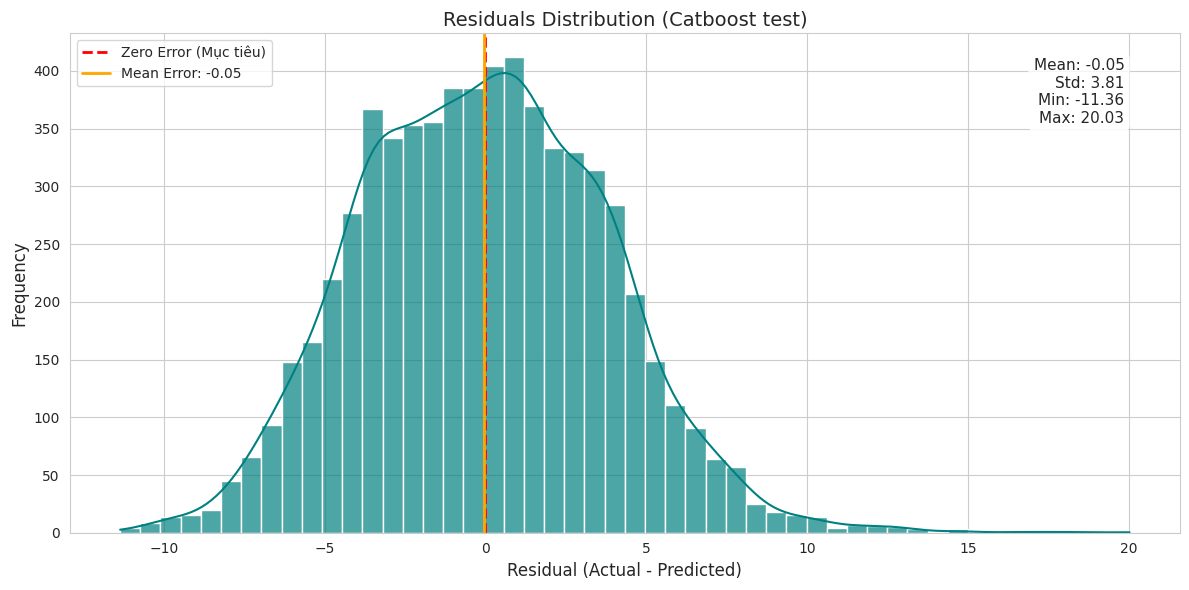

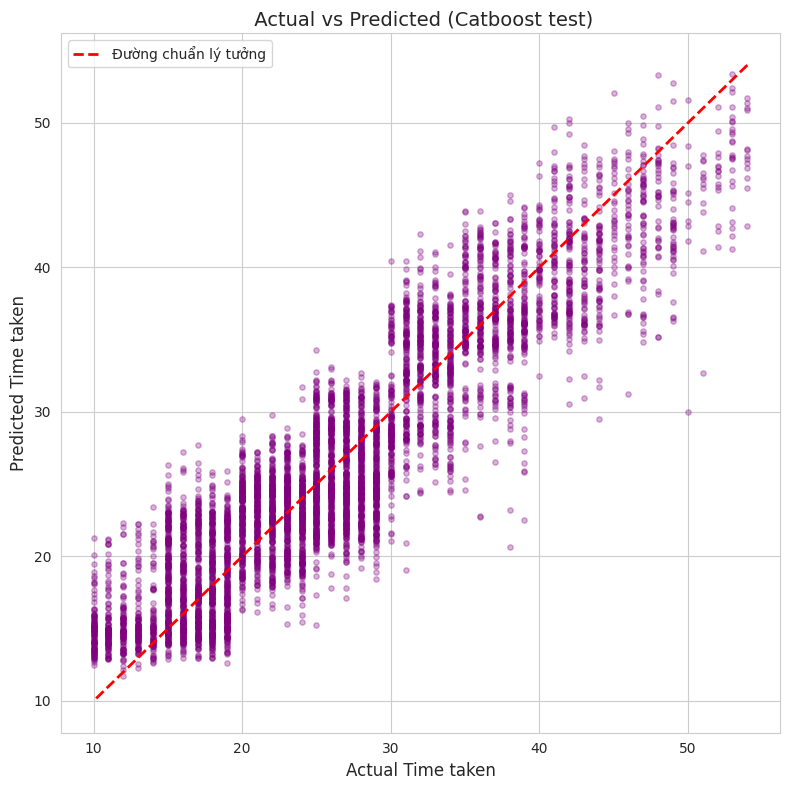

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# =================================================
# TRỰC QUAN HÓA KẾT QUẢ (MODEL RÚT GỌN)
# =================================================

# 1. Chuẩn bị dữ liệu vẽ (đảm bảo định dạng numpy array 1 chiều)
# y_test: Giá trị thực tế
# y_test_pred: Giá trị dự đoán từ reduced_model (đã tính ở code trên của bạn)

y_true_viz = y_test.values.flatten() if hasattr(y_test, 'values') else np.array(y_test).flatten()
y_pred_viz = y_test_pred.flatten()

# Tính toán sai số
residuals = y_true_viz - y_pred_viz

# Thiết lập style
sns.set_style("whitegrid")

# --- BIỂU ĐỒ 2: PHÂN PHỐI SAI SỐ (RESIDUALS) ---
plt.figure(figsize=(12, 6))

# Vẽ Histogram và đường mật độ (KDE)
sns.histplot(residuals, bins=50, kde=True, color='teal', edgecolor='white', alpha=0.7)

# Tính thống kê
mean_res = np.mean(residuals)
std_res = np.std(residuals)

# Vẽ đường trung bình
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Zero Error (Mục tiêu)')
plt.axvline(x=mean_res, color='orange', linestyle='-', linewidth=2, label=f'Mean Error: {mean_res:.2f}')

plt.title('Residuals Distribution (Catboost test)', fontsize=14)
plt.xlabel('Residual (Actual - Predicted)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend()

# Ghi chú thống kê lên biểu đồ
stats_text = f"Mean: {mean_res:.2f}\nStd: {std_res:.2f}\nMin: {np.min(residuals):.2f}\nMax: {np.max(residuals):.2f}"
plt.gca().text(0.95, 0.95, stats_text, transform=plt.gca().transAxes,
               fontsize=11, verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()

# --- BIỂU ĐỒ 3: SCATTER PLOT (ĐỘ CHỤM) ---
plt.figure(figsize=(8, 8))
plt.scatter(y_true_viz, y_pred_viz, alpha=0.3, color='purple', s=15)

# Đường chuẩn y=x (Màu đỏ)
p1 = max(np.max(y_pred_viz), np.max(y_true_viz))
p2 = min(np.min(y_pred_viz), np.min(y_true_viz))
plt.plot([p1, p2], [p1, p2], 'r--', lw=2, label='Đường chuẩn lý tưởng')

plt.xlabel('Actual Time taken', fontsize=12)
plt.ylabel('Predicted Time taken', fontsize=12)
plt.title(' Actual vs Predicted (Catboost test)', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()


Mức độ quan trọng của các biến:
                   feature  importance
6          weather_traffic   25.206085
5              distance_km   19.062301
0      delivery_person_age   17.216424
2        vehicle_condition   13.414803
1  delivery_person_ratings   11.409730
8                 hour_sin    3.791457
3      multiple_deliveries    3.516027
7             traffic_city    2.270286
9                 hour_cos    2.090193
4                 festival    2.022695


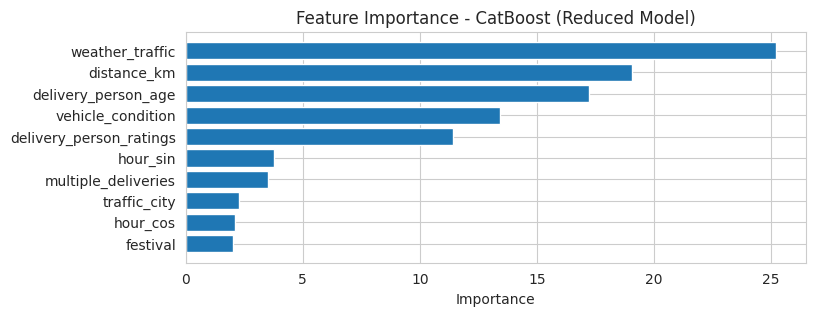

In [ ]:
feature_importance = reduced_model.get_feature_importance()
feature_names = reduced_model.feature_names_

fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importance
}).sort_values(by="importance", ascending=False)

print("\nMức độ quan trọng của các biến:")
print(fi_df)

plt.figure(figsize=(8, len(fi_df)*0.3))
plt.barh(fi_df["feature"], fi_df["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Feature Importance - CatBoost (Reduced Model)")
plt.show()